In [76]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE = "#4472C4"

import os
import psycopg2
from dotenv import load_dotenv

load_dotenv()

conn = psycopg2.connect(
    host=os.environ["DB_HOST"],
    port=os.environ["DB_PORT"],
    dbname=os.environ["DB_NAME"],
    user=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
)


def load_dataframe(table_name, conn, schema=None, preserve_case=False):
    from psycopg2 import sql
    if not isinstance(table_name, str) or not table_name.strip():
        raise ValueError("table_name must be a nonempty SQL table name")
    name = table_name if preserve_case else table_name.lower()
    identifier = sql.Identifier(schema, name) if schema else sql.Identifier(name)
    with conn.cursor() as cur:
        cur.execute(sql.SQL("SELECT * FROM {}").format(identifier))
        return pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])


def _frame(data, conn=None, schema=None, preserve_case=False):
    if isinstance(data, pd.DataFrame):
        return data.copy()
    if isinstance(data, str):
        if conn is None:
            raise ValueError("Pass conn=your_connection when data is a SQL table name")
        return load_dataframe(data, conn, schema, preserve_case)
    raise TypeError("data must be a pandas DataFrame or a SQL table name")


def _finish(fig, output_dir, filename):
    if output_dir is not None:
        folder = Path(output_dir)
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / filename, dpi=300, bbox_inches="tight")
    return fig


def missing_summary(data, **source):
    #Per column: dtype, missing count/share, and unique nonmissing values
    d = _frame(data, **source)
    return pd.DataFrame({"dtype": d.dtypes.astype(str), "n_missing": d.isna().sum(),
                         "share_missing": d.isna().mean(), "n_unique": d.nunique()})


def quantity_summary(data, by="bc_prescribed", **source):
    #Count and numeric summary of quantity per group; retain missing groups
    d = _frame(data, **source)
    return d.groupby(by, dropna=False)["quantity"].agg(
        ["count", "mean", "median", "std", "min", "max"])


def monthly_counts(data, date_col="date_order_placed", **source):
    #Records per calendar month, including zero months within the date span
    dates = pd.to_datetime(_frame(data, **source)[date_col], errors="coerce")
    counts = dates.dt.to_period("M").value_counts().sort_index()
    if not counts.empty:
        counts = counts.reindex(pd.period_range(counts.index.min(), counts.index.max(), freq="M"), fill_value=0)
    return counts.rename_axis("month").reset_index(name="n_records")


def prescriptions_per_patient(data, patient_col="patient_id", **source):
    #RxWritten row count per nonmissing patient ID
    d = _frame(data, **source)
    return d.groupby(patient_col).size().rename("n_prescriptions").reset_index()


def customer_ages(data, as_of=None, patient_col="patient_id", dob_col="customer_dob", **source):
    #Age per patient at as_of (today by default), using first DOB as in notebook

    #Missing patient IDs are excluded
    # Invalid DOBs become missing ages

    d = _frame(data, **source).dropna(subset=[patient_col])
    d[dob_col] = pd.to_datetime(d[dob_col], errors="coerce")
    if d.groupby(patient_col)[dob_col].nunique().gt(1).any():
        raise ValueError("Conflicting DOBs for a patient; resolve before calculating ages")
    d = d[[patient_col, dob_col]].drop_duplicates(patient_col).copy()
    date = pd.Timestamp.today().normalize() if as_of is None else pd.Timestamp(as_of).normalize()
    dob = d[dob_col]
    pending = (dob.dt.month > date.month) | ((dob.dt.month == date.month) & (dob.dt.day > date.day))
    d["age"] = (date.year - dob.dt.year - pending.astype(int)).astype("Int64")
    #Future DOBs remain visible as negative ages
    return d


def time_delays(data, start_col, end_col, unit="hours", **source):

    seconds = {"days": 86400, "hours": 3600, "minutes": 60}
    if unit not in seconds:
        raise ValueError("unit must be 'days', 'hours', or 'minutes'")
    d = _frame(data, **source)
    start = pd.to_datetime(d[start_col], errors="coerce")
    end = pd.to_datetime(d[end_col], errors="coerce")
    d[f"delay_{unit}"] = (end - start).dt.total_seconds() / seconds[unit]
    return d


def plot_histogram(data, column, hue=None, bins="auto", binwidth=None,
                   discrete=False, title=None, xlabel=None, ylabel="Number of records",
                   color=BLUE, xlim=None, output_dir="EDA", filename=None, **source):
    """Histogram of a column, optionally grouped; xlim changes view only."""
    d = _frame(data, **source)
    fig, ax = plt.subplots(figsize=(10, 6))
    if d[column].notna().any():
        # Give constant-valued inputs a real bin span
        if binwidth is not None:
            if binwidth <= 0:
                raise ValueError("binwidth must be positive")
            values = d[column].dropna()
            if values.min() == values.max():
                bins = [float(values.min()) - binwidth / 2,
                        float(values.max()) + binwidth / 2]
                binwidth = None
        sns.histplot(data=d, x=column, hue=hue, bins=bins, binwidth=binwidth,
                     discrete=discrete, color=color, ax=ax)
    else:
        ax.text(.5, .5, "No nonmissing values", transform=ax.transAxes, ha="center")
    ax.set(title=title or column, xlabel=xlabel or column, ylabel=ylabel)
    if xlim is not None:
        ax.set_xlim(xlim)
    fig.tight_layout()
    return _finish(fig, output_dir, filename or f"hist_{column}{'_by_' + hue if hue else ''}.png")


def plot_refills(data, kind="hist", output_dir="EDA", **source):
    #Refills allowed per order
    #Full range shown
    if kind == "hist":
        return plot_histogram(data, "refills_allowed", discrete=True,
                              title="Refills allowed per order", xlabel="Refills allowed",
                              ylabel="Number of orders", output_dir=output_dir, **source)
    if kind != "box":
        raise ValueError("kind must be 'hist' or 'box'")
    values = _frame(data, **source)["refills_allowed"].dropna()
    fig, ax = plt.subplots(figsize=(8, 6))
    if not values.empty:
        ax.boxplot(values)
    else:
        ax.text(.5, .5, "No nonmissing values", transform=ax.transAxes, ha="center")
    ax.set(title="Refills allowed per order", ylabel="Refills allowed")
    fig.tight_layout()
    return _finish(fig, output_dir, "boxplot_refills.png")


def plot_quantity(data, by_bc=False, **kwargs):
    #Quantity distribution per order, optionally grouped by birth-control flag
    return plot_histogram(data, "quantity", hue="bc_prescribed" if by_bc else None,
                          title="Quantity prescribed", xlabel="Quantity",
                          ylabel="Number of orders", **kwargs)


def plot_category_counts(data, column, title=None, output_dir="EDA", filename=None, **source):
    #Record counts per observed category; missing values have a separate bar
    counts = _frame(data, **source)[column].value_counts(dropna=False)
    labels = ["(missing)" if pd.isna(v) else str(v) for v in counts.index]
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(range(len(counts)), counts.values, color=BLUE)
    ax.set_xticks(range(len(counts)), labels, rotation=45, ha="right")
    ax.set(title=title or f"Record count by {column}", xlabel=column, ylabel="Number of records")
    fig.tight_layout()
    return _finish(fig, output_dir, filename or f"counts_{column}.png")


def plot_monthly_orders(data, date_col="date_order_placed", output_dir="EDA", **source):
    #Orders placed per month, preserving year and including zero months
    counts = monthly_counts(data, date_col, **source)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(counts["month"].astype(str), counts["n_records"], color=BLUE)
    ax.set(title="Orders placed by month", xlabel="Month", ylabel="Number of orders")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    return _finish(fig, output_dir, "orders_by_month.png")


def plot_prescriptions_per_patient(data, grouped=False, output_dir="EDA", **source):
    #RxWritten records per patient, or one vs multiple prescriptions
    counts = prescriptions_per_patient(data, **source)
    if not grouped:
        return plot_histogram(counts, "n_prescriptions", discrete=True,
                              title="Prescriptions written per patient", xlabel="Prescriptions",
                              ylabel="Number of patients", output_dir=output_dir)
    n = counts["n_prescriptions"]
    totals = [(n == 1).sum(), (n > 1).sum()]
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(["One prescription", "Multiple prescriptions"], totals, color=[BLUE, "#70AD47"])
    total = sum(totals)
    ax.bar_label(bars, labels=[f"{v:,}\n({v / total:.1%})" if total else "0" for v in totals], padding=5)
    ax.set(title="Patients with one versus multiple prescriptions written", ylabel="Number of patients",
           ylim=(0, max(1, max(totals) * 1.25)))
    fig.tight_layout()
    return _finish(fig, output_dir, "one_vs_multiple_prescriptions.png")


def plot_customer_age(data, as_of=None, output_dir="EDA", **source):
    #Age distribution, one record per patient, in five-year bins
    ages = customer_ages(data, as_of=as_of, **source)
    return plot_histogram(ages, "age", binwidth=5, title="Age distribution of customers",
                          xlabel="Age (years)", ylabel="Number of patients", output_dir=output_dir)


def plot_delay(data, start_col, end_col, unit="hours", nonnegative=False,
               upper_quantile=None, bins=30, binwidth=None, xlim=None,
               title="Time between events", output_dir="EDA", filename=None, **source):
    if upper_quantile is not None and not 0 < upper_quantile <= 1:
        raise ValueError("upper_quantile must be in (0, 1]")
    d = time_delays(data, start_col, end_col, unit, **source)
    col = f"delay_{unit}"
    values = d[col]
    missing = int(values.isna().sum())
    negative = int((values < 0).sum()) if nonnegative else 0
    shown = d.loc[values.notna() & ((values >= 0) if nonnegative else True)].copy()
    trimmed = 0
    if upper_quantile is not None and not shown.empty:
        cutoff = shown[col].quantile(upper_quantile)
        trimmed = int((shown[col] > cutoff).sum())
        shown = shown.loc[shown[col] <= cutoff]
    fig = plot_histogram(shown, col, bins=bins, binwidth=binwidth, title=title,
                         xlabel=f"Delay ({unit})", xlim=xlim, output_dir=None)
    fig.axes[0].text(.98, .95, f"Excluded: {missing} missing delays\n{negative} negative delays\n"
                    f"{trimmed} delays above quantile cutoff", transform=fig.axes[0].transAxes,
                    ha="right", va="top", fontsize=9)
    return _finish(fig, output_dir, filename or f"{end_col}_minus_{start_col}_{unit}.png")


def plot_entry_delay(data, **kwargs):
    #Creation minus writing in hours
    #nonnegative delays through 99th percentile
    options = dict(unit="hours", nonnegative=True, upper_quantile=.99,
                   title="Time from prescription writing to entry", filename="prescription_entry_delay.png")
    options.update(kwargs)
    return plot_delay(data, "rx_written_date_time", "rx_creation_date_time", **options)


def plot_packing_delay(data, **kwargs):
    #Packing minus receipt in minutes
    #nonnegative through 99th percentile
    options = dict(unit="minutes", nonnegative=True, upper_quantile=.99,
                   title="Time from order receipt to packing", filename="packing_delay_minutes.png")
    options.update(kwargs)
    return plot_delay(data, "order_receipt_date_time", "packed_date_time", **options)


def plot_payment_delay(data, **kwargs):
    #Payment minus placement days
    #All valid delays retained
    options = dict(unit="days", binwidth=1, title="Time from order placement to payment",
                   filename="payment_delay_days.png")
    options.update(kwargs)
    return plot_delay(data, "date_order_placed", "date_order_paid", **options)


def shipment_state_counts(data, state_col="state", **source):
    state = _frame(data, **source)[state_col].astype("string").str.strip().str.upper()
    return state.replace("", pd.NA).value_counts().rename_axis("state").reset_index(name="shipments")


def plot_shipments_by_state(data, output_dir="EDA", filename="shipments_by_state.html", **source):
    import plotly.express as px
    d = _frame(data, **source)
    counts = shipment_state_counts(d)
    valid = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
    invalid = counts.loc[~counts["state"].isin(valid), "state"].tolist()
    if invalid:
        raise ValueError(f"Non-US-state codes require review before mapping: {invalid}")
    fig = px.choropleth(counts, locations="state", locationmode="USA-states", color="shipments",
                        scope="usa", color_continuous_scale="Blues", title="Shipment count by state")
    missing = len(d) - counts["shipments"].sum()
    fig.add_annotation(text=f"Missing/blank state: {missing}", x=0, y=0, xref="paper", yref="paper", showarrow=False)
    fig.update_layout(title_x=.5, margin=dict(l=0, r=0, t=60, b=0))
    if output_dir is not None:
        folder = Path(output_dir)
        folder.mkdir(parents=True, exist_ok=True)
        fig.write_html(folder / filename, include_plotlyjs=True)
    return fig

def order_status_summary(data, status_col="status", **source):
    #Count and percentage of order records in each status
    #missing, processed or archived
    d = _frame(data, **source)

    # Treat blank strings and SQL nulls as missing.
    status = d[status_col].astype("string").str.strip()
    status = status.replace("", pd.NA).fillna("(missing)")

    summary = (
        status.value_counts()
        .rename_axis("status")
        .reset_index(name="n_orders")
    )

    summary["percent_orders"] = (
        summary["n_orders"] / len(d) * 100
        if len(d) else 0.0
    )

    return summary

def plot_approval_flags(
    data,
    flags=None,
    output_dir="EDA",
    filename="approval_flags.png",
    **source,
):
    #Plot true, false, and missing counts for approval/suspension flags
    d = _frame(data, **source)

    if flags is None:
        flags = {
            "customer_approved": "Customer approved",
            "adyn_approved": "Adyn approved",
            "suspended": "Suspended",
        }
 

    if not flags:
        raise ValueError("Provide at least one flag column.")

    rows = []

    for column, label in flags.items():
        # Accept booleans and common string/numeric representations.
        values = (
            d[column]
            .astype("string")
            .str.strip()
            .str.lower()
            .replace("", pd.NA)
        )

        mapping = {
            "true": "True",
            "false": "False",
            "1": "True",
            "0": "False",
            "1.0": "True",
            "0.0": "False",
        }

        unknown = values.notna() & ~values.isin(mapping.keys())

        if unknown.any():
            raise ValueError(
                f"Unrecognized values in {column}: "
                f"{values[unknown].unique().tolist()}. "
                "Update mapping after confirming their meaning."
            )

        counts = (
            values.map(mapping)
            .fillna("Missing")
            .value_counts()
        )

        for value in ["True", "False", "Missing"]:
            rows.append({
                "flag": label,
                "value": value,
                "n_orders": int(counts.get(value, 0)),
            })

    counts = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        data=counts,
        x="flag",
        y="n_orders",
        hue="value",
        order=list(flags.values()),
        hue_order=["True", "False", "Missing"],
        palette={
            "True": "#4472C4",
            "False": "#70AD47",
            "Missing": "#A6A6A6",
        },
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)

    ax.set(
        title="Order approval and suspension flags",
        xlabel="",
        ylabel="Number of orders",
    )
    ax.legend(title="Recorded value")
    ax.margins(y=0.15)

    fig.tight_layout()
    return _finish(fig, output_dir, filename)
#investigates payment delays by stock keeping unit (product type)
def payment_delay_summary(
    data,
    group="sku",
    nonnegative=True,
    **source,
):
    """Payment-delay statistics per group, in days."""
    d = time_delays(
        data,
        start_col="date_order_placed",
        end_col="date_order_paid",
        unit="days",
        **source,
    )

    rows = []

    for name, g in d.groupby(group, dropna=False, observed=True):
        delays = g["delay_days"].dropna()
        negative = delays.lt(0).sum()

        if nonnegative:
            delays = delays[delays >= 0]

        rows.append({
            group: name,
            "n_orders": len(g),
            "n_missing_delay": g["delay_days"].isna().sum(),
            "n_negative_delay": negative,
            "n_analyzed": len(delays),
            "median_days": delays.median(),
            "mean_days": delays.mean(),
            "p90_days": delays.quantile(0.90),
        })

    return pd.DataFrame(
        rows,
        columns=[
            group, "n_orders", "n_missing_delay",
            "n_negative_delay", "n_analyzed",
            "median_days", "mean_days", "p90_days",
        ],
    )
def plot_payment_delay_by(
    data,
    group="sku",
    nonnegative=True,
    showfliers=True,
    output_dir="EDA",
    filename=None,
    **source,
):
    # Compare payment delays across groups using boxplots.
    d = time_delays(
        data,
        start_col="date_order_placed",
        end_col="date_order_paid",
        unit="days",
        **source,
    )

    # Retain missing group values as their own category.
    d["_group"] = d[group].astype("string").fillna("(missing)")

    missing = int(d["delay_days"].isna().sum())
    negative = int(d["delay_days"].lt(0).sum())

    shown = d.dropna(subset=["delay_days"]).copy()

    if nonnegative:
        shown = shown[shown["delay_days"] >= 0]

    fig, ax = plt.subplots(figsize=(12, 6))

    if shown.empty:
        ax.text(
            0.5,
            0.5,
            "No usable payment delays",
            transform=ax.transAxes,
            ha="center",
        )
    else:
        order = (
            shown.groupby("_group")["delay_days"]
            .median()
            .sort_values()
            .index.tolist()
        )

        sns.boxplot(
            data=shown,
            x="_group",
            y="delay_days",
            order=order,
            showfliers=showfliers,
            color="#4472C4",
            ax=ax,
        )

        counts = shown["_group"].value_counts()

        ax.set_xticks(
            range(len(order)),
            [f"{name}\n(n={counts[name]})" for name in order],
            rotation=45,
            ha="right",
        )

    ax.set(
        title=f"Time to payment by {group}",
        xlabel=group,
        ylabel="Time to payment (days)",
    )

    excluded_negative = negative if nonnegative else 0

    fig.text(
        0.01,
        0.01,
        f"Excluded: {missing} missing delays; "
        f"{excluded_negative} negative delays.",
        fontsize=9,
    )

    fig.tight_layout(rect=(0, 0.05, 1, 1))

    return _finish(
        fig,
        output_dir,
        filename or f"payment_delay_by_{group}.png",
    )


def monthly_delay_summary(
    data,
    start_col,
    end_col,
    unit="days",
    nonnegative=True,
    **source,
):
    # Monthly median and 90th-percentile delay, plus record counts
    d = time_delays(
        data,
        start_col=start_col,
        end_col=end_col,
        unit=unit,
        **source,
    )

    delay_col = f"delay_{unit}"
    start = pd.to_datetime(d[start_col], errors="coerce")
    d["_month"] = start.dt.to_period("M")

    valid_start = d["_month"].notna()
    missing_start = int((~valid_start).sum())

    columns = [
        "month",
        "n_records",
        "n_missing_delay",
        "n_negative_delay",
        "n_analyzed",
        "median",
        "p90",
    ]

    if not valid_start.any():
        result = pd.DataFrame(columns=columns)
        result.attrs["n_missing_start_date"] = missing_start
        return result

    rows = []

    for month, g in d.loc[valid_start].groupby("_month"):
        delays = g[delay_col].dropna()
        negative = int(delays.lt(0).sum())

        if nonnegative:
            delays = delays[delays >= 0]

        rows.append(
            {
                "month": month,
                "n_records": len(g),
                "n_missing_delay": int(g[delay_col].isna().sum()),
                "n_negative_delay": negative,
                "n_analyzed": len(delays),
                "median": delays.median(),
                "p90": delays.quantile(0.90),
            }
        )

    result = pd.DataFrame(rows).set_index("month")

    # Keep months with no records; their delay statistics remain missing
    months = pd.period_range(
        result.index.min(),
        result.index.max(),
        freq="M",
    )

    result = result.reindex(months).rename_axis("month")

    count_cols = [
        "n_records",
        "n_missing_delay",
        "n_negative_delay",
        "n_analyzed",
    ]

    result[count_cols] = result[count_cols].fillna(0).astype(int)

    result = result.reset_index()
    result.attrs["n_missing_start_date"] = missing_start

    return result


def plot_delay_trend(
    data,
    start_col,
    end_col,
    unit="days",
    nonnegative=True,
    min_n=1,
    title=None,
    output_dir="EDA",
    filename=None,
    **source,
):
    # Monthly median/p90 delay and the number of analyzed records
    if min_n < 1:
        raise ValueError("min_n must be at least 1.")

    summary = monthly_delay_summary(
        data,
        start_col=start_col,
        end_col=end_col,
        unit=unit,
        nonnegative=nonnegative,
        **source,
    )

    fig, (ax, count_ax) = plt.subplots(
        2,
        1,
        figsize=(12, 8),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )

    if summary.empty:
        ax.text(
            0.5,
            0.5,
            "No usable start dates",
            transform=ax.transAxes,
            ha="center",
        )
    else:
        dates = summary["month"].dt.to_timestamp()
        enough = summary["n_analyzed"] >= min_n

        ax.plot(
            dates,
            summary["median"].where(enough),
            marker="o",
            label="Median",
            color="#4472C4",
        )

        ax.plot(
            dates,
            summary["p90"].where(enough),
            marker="o",
            label="90th percentile",
            color="#70AD47",
        )

        ax.legend()

        count_ax.bar(
            dates,
            summary["n_analyzed"],
            width=20,
            color="#A6A6A6",
        )

    ax.set(
        title=title or f"Monthly delay: {start_col} to {end_col}",
        ylabel=f"Delay ({unit})",
    )

    count_ax.set(
        xlabel="Start-event month",
        ylabel="Records\nanalyzed",
    )

    missing_start = summary.attrs["n_missing_start_date"]

    fig.text(
        0.01,
        0.01,
        f"Records without a usable start date: {missing_start}. "
        f"Delay lines require at least {min_n} usable records per month.",
        fontsize=9,
    )

    fig.autofmt_xdate()
    fig.tight_layout(rect=(0, 0.05, 1, 1))

    return _finish(
        fig,
        output_dir,
        filename or f"monthly_delay_{start_col}_to_{end_col}.png",
    )
def check_order_shipment_links(rx_orders, rx_shipments):
    #Check order IDs and how many shipment records each order has
    shipments_per_order = (
        rx_shipments.groupby("rx_order_id").size()
    )

    return pd.DataFrame([{
        "duplicate_order_ids": rx_orders["id"].duplicated().sum(),
        "shipments_missing_order_id": (
            rx_shipments["rx_order_id"].isna().sum()
        ),
        "orders_with_multiple_shipments": (
            shipments_per_order.gt(1).sum()
        ),
        "shipments_with_unmatched_order_id": (
            rx_shipments["rx_order_id"].notna()
            & ~rx_shipments["rx_order_id"].isin(rx_orders["id"])
        ).sum(),
    }])


def check_cost_links(rx_orders, rx_packed, rx_matches):
    #Check whether RxMatches can connect orders to packing/cost records
    links = rx_matches[["rx_order_id", "rx_packed_id"]]

    return pd.DataFrame([{
        "match_rows": len(links),
        "missing_order_id": links["rx_order_id"].isna().sum(),
        "missing_packed_id": links["rx_packed_id"].isna().sum(),
        "duplicate_link_pairs": links.duplicated().sum(),
        "orders_with_multiple_packed_ids": (
            links.groupby("rx_order_id")["rx_packed_id"]
            .nunique()
            .gt(1)
            .sum()
        ),
        "packed_ids_linked_to_multiple_orders": (
            links.groupby("rx_packed_id")["rx_order_id"]
            .nunique()
            .gt(1)
            .sum()
        ),
        "unmatched_order_ids": (
            links["rx_order_id"].notna()
            & ~links["rx_order_id"].isin(rx_orders["id"])
        ).sum(),
        "unmatched_packed_ids": (
            links["rx_packed_id"].notna()
            & ~links["rx_packed_id"].isin(rx_packed["id"])
        ).sum(),
    }])
def repeat_order_summary(
    rx_orders,
    customer_col="customer_id",
    order_col="id",
):
    #One row per customer: distinct orders and whether they ordered again
    summary = (
        rx_orders.dropna(subset=[customer_col])
        .groupby(customer_col)[order_col]
        .nunique()
        .reset_index(name="n_orders")
    )

    summary["repeat_customer"] = summary["n_orders"] > 1

    return summary
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


def customer_milestone_summary(paid_orders, milestones, customer_col="customer_id"):
    """Count unique paying customers who meet each milestone.

    milestones is a dictionary:
        "Milestone label": (DataFrame, customer ID column, boolean condition)

    Only customers with a nonmissing date_order_paid are included.
    """
    paying_ids = pd.Index(
        paid_orders.loc[
            paid_orders["date_order_paid"].notna(),
            customer_col,
        ].dropna().unique()
    )

    total = len(paying_ids)

    rows = [{
        "milestone": "Paying customers",
        "n_customers": total,
        "percent_of_paying_customers": 100.0 if total else float("nan"),
        "configured": True,
    }]

    for label, config in milestones.items():
        # Unconfigured milestones stay missing rather than appearing as zero.
        if config is None:
            rows.append({
                "milestone": label,
                "n_customers": pd.NA,
                "percent_of_paying_customers": float("nan"),
                "configured": False,
            })
            continue

        data, id_col, condition = config

        if not isinstance(condition, pd.Series):
            raise TypeError(f"{label}: condition must be a boolean Series.")

        if not condition.index.equals(data.index):
            raise ValueError(f"{label}: condition must align with its DataFrame.")

        if not pd.api.types.is_bool_dtype(condition.dtype):
            raise TypeError(f"{label}: condition must contain boolean values.")

        # A customer counts once, even if they have multiple matching records.
        matched_ids = pd.Index(
            data.loc[condition.fillna(False), id_col].dropna().unique()
        )

        count = len(paying_ids.intersection(matched_ids))

        rows.append({
            "milestone": label,
            "n_customers": count,
            "percent_of_paying_customers": (
                count / total * 100 if total else float("nan")
            ),
            "configured": True,
        })

    summary = pd.DataFrame(rows)
    summary["n_customers"] = summary["n_customers"].astype("Int64")

    return summary




In [77]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# CHANGE the column names on the left to match your prepared customer data.
# Labels on the right control how the summary and plot display each milestone.
CUSTOMER_MILESTONES = {
    "profile_complete": "Completed profile",
    "por_order_approved": "PoR order approval", #orders_approvers status
    "admin_order_approved": "Admin order approval",
    "test_shipped": "Test shipped",
    "test_delivered": "At least one test delivered",
    "medbio_complete": "Completed medical biography",
    "dna_returned": "DNA returned",
    "valid_dna_sample": "At least one valid DNA sample",
    "blood_returned": "Blood returned",
    "valid_blood_sample": "At least one valid blood sample",
    "results_generated": "Results generated",
    "admin_results_approved": "Admin result approval",
    "por_results_approved": "PoR result approval",
    "results_viewed": "Results viewed by customer",
    "virtual_care_booked": "At least one virtual care booking",
    "virtual_care_completed": "At least one completed virtual care visit",
    "has_rx": "At least one Rx record",
    "multiple_virtual_care_visits": "More than one virtual care visit",
}


def customer_progress_summary(
    customers,
    milestones,
    customer_col="customer_id",
):
    """Count each milestone across all customers, without filtering by payment."""
    required = [customer_col, *milestones]
    missing_columns = [
        column for column in required
        if column not in customers.columns
    ]

    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    if customers[customer_col].isna().any():
        raise ValueError("Customer IDs must not be missing.")

    if customers[customer_col].duplicated().any():
        raise ValueError("Expected one row per customer.")

    total = len(customers)
    rows = []

    for column, label in milestones.items():
        values = customers[column]

        if not values.dropna().isin([True, False]).all():
            raise ValueError(
                f"{column} must contain True, False, or missing values."
            )

        count = int(values.eq(True).sum())

        rows.append({
            "milestone": label,
            "n_customers": count,
            "percent_all_customers": (
                count / total * 100 if total else float("nan")
            ),
            "n_unknown": int(values.isna().sum()),
        })

    return pd.DataFrame(rows)

def plot_customer_progress(
    summary,
    title="Customer milestones among paid customers",
    output_dir="EDA",
    filename="customer_progress.png",
):
    """Return a horizontal bar chart and optionally save it."""
    height = max(6, len(summary) * 0.42)
    fig, ax = plt.subplots(figsize=(13, height))

    bars = ax.barh(
        range(len(summary)),
        summary["n_customers"],
        color="#4472C4",
    )

    ax.set_yticks(range(len(summary)), summary["milestone"])
    ax.invert_yaxis()

    labels = [
        (
            f"{int(row.n_customers):,} ({row.percent_paid_customers:.1f}%)"
            if pd.notna(row.percent_paid_customers)
            else f"{int(row.n_customers):,} (N/A)"
        )
        for row in summary.itertuples()
    ]

    ax.bar_label(bars, labels=labels, padding=5, fontsize=9)

    maximum = summary["n_customers"].max()
    ax.set_xlim(0, max(1, maximum * 1.3))

    ax.set(
        title=title,
        xlabel="Number of customers",
        ylabel="",
    )
    ax.spines[["top", "right"]].set_visible(False)

    fig.text(
        0.01,
        0.01,
        "Percentages use all paid customers. Milestones are counted independently.",
        fontsize=9,
    )

    fig.tight_layout(rect=(0, 0.04, 1, 1))

    if output_dir is not None:
        folder = Path(output_dir)
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / filename, dpi=300, bbox_inches="tight")

    return fig

In [78]:
def prepare_customer_flags(data, conditions, customer_col="customer_id"):
    """Turn record-level conditions into customer-level milestone flags.

    conditions:
        Dictionary of output column names and functions returning
        True/False/missing for each source row.

    A customer is True if any record is True.
    Otherwise, missing conditions remain unknown.
    """
    d = data.loc[data[customer_col].notna()].copy()
    flags = pd.DataFrame(index=d.index)

    for name, condition in conditions.items():
        values = condition(d).astype("boolean")
        flags[name] = values

    flags[customer_col] = d[customer_col]

    def any_with_unknown(values):
        if values.fillna(False).any():
            return True
        if values.isna().any():
            return pd.NA
        return False

    return (
        flags.groupby(customer_col)[list(conditions)]
        .agg(any_with_unknown)
        .astype("boolean")
        .reset_index()
    )



def merge_customer_milestones(
    customers,
    payments,
    milestone_tables,
    customer_col="customer_id",
    paid_date_col="date_order_paid",
    milestones=None,
    absent_means_false=None,
):
    """Left-merge prepared tables and validate input for the summary function.

    milestone_tables:
        Dictionary such as {"profiles": profile_flags, "samples": sample_flags}.

    absent_means_false:
        Milestone columns where NO matching source record definitively means
        False. Missing values within matching source records remain unknown.
    """
    if milestones is None:
        milestones = CUSTOMER_MILESTONES

    absent_means_false = set(absent_means_false or [])

    invalid = absent_means_false - set(milestones)
    if invalid:
        raise ValueError(f"Unknown milestone columns: {sorted(invalid)}")

    result = customers[[customer_col]].copy()

    if result[customer_col].isna().any():
        raise ValueError("Customers table contains missing customer IDs.")

    if result[customer_col].duplicated().any():
        raise ValueError("Customers table must have one row per customer.")

    tables = [
        ("payments", payments),
        *milestone_tables.items(),
    ]

    for name, table in tables:
        if customer_col not in table.columns:
            raise ValueError(f"{name}: missing {customer_col}.")

        if table[customer_col].isna().any():
            raise ValueError(f"{name}: contains missing customer IDs.")

        if table[customer_col].duplicated().any():
            raise ValueError(
                f"{name}: multiple rows per customer. Aggregate first."
            )

        overlap = (set(result.columns) & set(table.columns)) - {customer_col}
        if overlap:
            raise ValueError(
                f"{name}: columns already present: {sorted(overlap)}"
            )

        # Record whether the customer has a row in this source table.
        matched = result[customer_col].isin(table[customer_col])

        result = result.merge(
            table,
            on=customer_col,
            how="left",
            validate="one_to_one",
            sort=False,
        )

        for column in absent_means_false & set(table.columns):
            result.loc[~matched.to_numpy(), column] = False

    required = [paid_date_col, *milestones]
    missing = [column for column in required if column not in result.columns]

    if missing:
        raise ValueError(
            f"Prepare these columns before summarizing: {missing}"
        )

    for column in milestones:
        if not result[column].dropna().isin([True, False]).all():
            raise ValueError(
                f"{column} must contain True, False, or missing."
            )
        result[column] = result[column].astype("boolean")

    return result

def merge_on_customer_id(left, right):
    return left.merge(right, on="customer_id", how="left")

In [79]:

rx_orders = load_dataframe("RxOrders", conn)
rx_written = load_dataframe("RxWritten", conn)
rx_shipments = load_dataframe("RxShipments", conn)
rx_packed = load_dataframe("RxPacked", conn)
rx_matches = load_dataframe("RxMatches", conn)
customers = load_dataframe("Customers", conn)
hubspot_tenants = load_dataframe("HubspotTenants", conn)
medical_bio_sub = load_dataframe("MedicalBioSubmissions", conn)
email_history = load_dataframe("EmailHistory", conn)
shipping_address = load_dataframe("ShippingAddresses", conn)
orders = load_dataframe("Orders", conn)
order_history = load_dataframe("OrderHistory", conn)
coupon_orders = load_dataframe("CouponOrders", conn)
payment_issues = load_dataframe("PaymentIssues", conn)
coupon_redeemers = load_dataframe("Coupons_Redeemers", conn)
orders_approvers = load_dataframe("Orders_Approvers", conn)
shipments = load_dataframe("Shipments", conn)
shipments_replacements = load_dataframe("Shipments_Replacements", conn)
samples = load_dataframe("Samples", conn)
sample_history = load_dataframe("SampleHistory", conn)
result_values = load_dataframe("ResultValues", conn)
result_values_history = load_dataframe("ResultValuesHistory", conn)
appointments = load_dataframe("Appointments", conn)
appointment_selections = load_dataframe("AppointmentSelections", conn)
profile_completions = load_dataframe("ProfileCompletions", conn)
variants = load_dataframe("Variants", conn)
genotype_values = load_dataframe("GenotypeValues", conn)
hormones = load_dataframe("Hormones", conn)
hormone_values = load_dataframe("HormoneValues", conn)
result_values_approvers = load_dataframe("ResultValues_Approvers", conn)



In [80]:
profile_completions['complete']

0       True
1      False
2       True
3      False
4       True
       ...  
313     True
314     True
315    False
316     True
317     True
Name: complete, Length: 318, dtype: bool

In [81]:
#check profile completion and people who paid

#profile_merged = merge_on_customer_id(customers, profile_completions)
profile_flags = prepare_customer_flags(
    profile_completions,  # CHANGE to your profile DataFrame.
    conditions={
        "profile_complete": lambda d: (
            d["complete"]  # CHANGE column name.
            .astype("string")
            .eq("True")      # CHANGE completion value.
        ),
    },
)
profile_data = (
    customers.rename(columns={"id": "customer_id"})
    .merge(
        profile_flags,
        on="customer_id",
        how="left",
        validate="one_to_one",
    )
)

assert profile_data["customer_id"].is_unique
assert len(profile_data) == len(customers)


print(profile_data["profile_complete"].value_counts(dropna=False))

# CHANGE payment_data to your payment/order DataFrame name.
# True if the customer has ANY record with a nonmissing payment date.
payment_flags = (
    orders.assign(
        has_paid_order=orders["date_order_paid"].notna()
    )
    .groupby("customer_id", as_index=False)
    .agg(has_paid_order=("has_paid_order", "any"))
)

profile_data = profile_data.merge(
    payment_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

assert profile_data["customer_id"].is_unique
assert len(profile_data) == len(customers)

#fill no matches with na, assume no payment received
profile_data["has_paid_order"] = (
    profile_data["has_paid_order"].astype("boolean").fillna(False)
)

profile_complete
<NA>    2051
True     263
Name: count, dtype: Int64


In [82]:
milestones = {
    "profile_complete": "Completed profile",
    "has_paid_order": "Customers with a paid order",
}

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0


In [83]:
# One row per customer.
assert profile_data["customer_id"].is_unique
assert len(profile_data) == len(customers)

# Review True, False, and missing values for each current milestone.
for column in milestones:
    print(f"\n{column}")
    print(profile_data[column].value_counts(dropna=False))

display(summary)


profile_complete
profile_complete
<NA>    2051
True     263
Name: count, dtype: Int64

has_paid_order
has_paid_order
False    1342
True      972
Name: count, dtype: Int64


,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0


In [84]:
orders['por_approved'].unique()

array([None, True, False], dtype=object)

In [85]:
#now check por and admin order approval
approval_flags = prepare_customer_flags(
    orders,  # CHANGE to your orders DataFrame.
    conditions={
        "por_order_approved": lambda d: (
            d["por_approved"]       # CHANGE column name.
            .astype("string")
            .eq("True")                # CHANGE approved value.
        ),
        "admin_order_approved": lambda d: (
            d["adyn_approved"]     # CHANGE column name.
            .astype("string")
            .eq("True")                # CHANGE approved value.
        ),
    },
)

In [86]:
profile_data = profile_data.merge(
    approval_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

milestones.update({
    "por_order_approved": "PoR order approval",
    "admin_order_approved": "Admin order approval",
})

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0
2,PoR order approval,216,9.334486,2098
3,Admin order approval,201,8.686258,2105


In [ ]:


order_customers = orders[["id", "customer_id"]].rename(
    columns={"id": "order_id"}
)

shipments_with_customers = shipments.merge(
    order_customers,
    on="order_id",
    how="left",
    validate="many_to_one",  # Multiple shipments can belong to one order.
)

# Check that each shipment successfully linked to a customer.
print(
    "Shipments without a matched customer:",
    shipments_with_customers["customer_id"].isna().sum(),
)

Shipments without a matched customer: 0


In [88]:
# Example for timestamps: True if an event date is recorded.
shipment_flags = prepare_customer_flags(
    shipments_with_customers, 
    conditions={
        "test_shipped": lambda d: d["date_shipped"].notna(),
        "test_delivered": lambda d: d["delivered_to_customer_date"].notna(),
        # CHANGE both date column names.
        # Filter to TEST shipments first if this table also contains Rx shipments.
    },
)

In [89]:
profile_data = profile_data.merge(
    shipment_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

milestones.update({
    "test_shipped": "Test shipped",
    "test_delivered": "At least one test delivered",
})

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0
2,PoR order approval,216,9.334486,2098
3,Admin order approval,201,8.686258,2105
4,Test shipped,196,8.470182,2118
5,At least one test delivered,195,8.426966,2118


In [90]:
medical_bio_sub['completion'].unique()

array([None], dtype=object)

In [91]:
#add medical biography completion
#all data currently None for completion, assume percentage out of 100
medbio_flags = prepare_customer_flags(
    medical_bio_sub,  
    conditions={
        "medbio_complete": lambda d: (
            d["completion"] 
            .astype("string")
            .eq("100")         
        ),
    },
)

In [92]:
print(medbio_flags["medbio_complete"].value_counts(dropna=False))

profile_data = profile_data.merge(
    medbio_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

milestones["medbio_complete"] = "Completed medical biography"

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

medbio_complete
<NA>    143
Name: count, dtype: Int64


,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0
2,PoR order approval,216,9.334486,2098
3,Admin order approval,201,8.686258,2105
4,Test shipped,196,8.470182,2118
5,At least one test delivered,195,8.426966,2118
6,Completed medical biography,0,0.000000,2314


In [106]:
shipments_with_customers.columns

Index(['id', 'order_id', 'tracking_number', 'date_shipped', 'shipped_via',
       'status', 'return_status1', 'return_status2', 'details',
       'return_details1', 'return_details2', 'return_tracking_number1',
       'return_tracking_number2', 'secondary_kit_id1', 'secondary_kit_id2',
       'created_date', 'modified_date', 'delivered_to_customer_date',
       'delivered_to_facility1_date', 'delivered_to_facility2_date',
       'status_checked', 'expiration_date1', 'expiration_date2', 'device_id',
       'shipped_to_facility1_date', 'shipped_to_facility2_date',
       'customer_id'],
      dtype='str')

In [109]:
#add dna information
#need to connect samples to shipments to customers
# CHANGE these placeholder column names:
# DNA_SHIPMENT_ID: shipment reference in your DNA DataFrame.
# SHIPMENT_ID: unique shipment ID in shipments_with_customers.

dna_with_customers = samples.merge(
    shipments_with_customers[["id", "customer_id"]],
    left_on="shipment_id",
    right_on="id",
    how="left",
    validate="many_to_one",
)

print(
    "DNA records without a matched customer:",
    dna_with_customers["customer_id"].isna().sum(),
)

DNA records without a matched customer: 0


In [113]:
dna_flags = prepare_customer_flags(
    dna_with_customers,
    conditions={
        "dna_returned": lambda d: (
            d["kind"].astype("string").eq("KIT-SLV")
            & d["received_by_lab_date"].notna()
        ),
        "valid_dna_sample": lambda d: (
            d["kind"].astype("string").eq("KIT-SLV")
            & d["status"].astype("string").eq("valid")
        ),
    },
)

In [ ]:
#add dna to table
profile_data = profile_data.merge(
    dna_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

milestones.update({
    "dna_returned": "DNA returned",
    "valid_dna_sample": "At least one valid DNA sample",
})

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0
2,PoR order approval,216,9.334486,2098
3,Admin order approval,201,8.686258,2105
4,Test shipped,196,8.470182,2118
5,At least one test delivered,195,8.426966,2118
6,Completed medical biography,0,0.000000,2314
7,DNA returned,195,8.426966,2119
8,At least one valid DNA sample,195,8.426966,2119


In [115]:
#investigate blood
blood_flags = prepare_customer_flags(
    dna_with_customers,
    conditions={
        "blood_returned": lambda d: (
            d["kind"].astype("string").eq("KIT-BLD")
            & d["received_by_lab_date"].notna()
        ),
        "valid_blood_sample": lambda d: (
            d["kind"].astype("string").eq("KIT-BLD")
            & d["status"].astype("string").eq("valid")
        ),
    },
)

In [116]:
#add blood to table
profile_data = profile_data.merge(
    blood_flags,
    on="customer_id",
    how="left",
    validate="one_to_one",
)

milestones.update({
    "blood_returned": "Blood returned",
    "valid_blood_sample": "At least one valid blood sample",
})

summary = customer_progress_summary(
    customers=profile_data,
    milestones=milestones,
)

display(summary)

,milestone,n_customers,percent_all_customers,n_unknown
0,Completed profile,263,11.365601,2051
1,Customers with a paid order,972,42.005186,0
2,PoR order approval,216,9.334486,2098
3,Admin order approval,201,8.686258,2105
4,Test shipped,196,8.470182,2118
5,At least one test delivered,195,8.426966,2118
6,Completed medical biography,0,0.000000,2314
7,DNA returned,195,8.426966,2119
8,At least one valid DNA sample,195,8.426966,2119
9,Blood returned,193,8.340536,2119


In [93]:
customers = repeat_order_summary(rx_orders)

display(customers.head())
print("Customers analyzed:", len(customers))
print(
    "Repeat-customer percentage:",
    round(customers["repeat_customer"].mean() * 100, 1),
)

,customer_id,n_orders,repeat_customer
0,009197a8-508e-4b66-b7b9-b4f1a0cd5720,4,True
1,01fb4f32-4711-4afa-b14b-7c0b02025cbc,1,False
2,0cd52b93-ced0-406e-b09d-5d3392ace8d0,2,True
3,0e66d81a-fb68-4716-b7ee-03ead438b80b,1,False
4,117fed00-a750-46c6-8844-f942b50fb0d6,1,False


Customers analyzed: 45
Repeat-customer percentage: 53.3


,sku,n_orders,n_missing_delay,n_negative_delay,n_analyzed,median_days,mean_days,p90_days
0,AD-BC-ALTAVE00,22,19,0,3,0.010259,1.269944,3.037957
1,AD-BC-DAYSEE00,43,26,1,16,0.004579,5.022643,16.576459
2,AD-BC-DEPOTP00,30,22,0,8,3.289916,53.820543,150.474195
3,AD-BC-DROS03LE,13,8,0,5,0.001851,0.215731,0.644047
4,AD-BC-EXTERNAL,4,2,0,2,0.000857,0.000857,0.001246
5,AD-BC-FALMIN20,31,17,0,14,0.127994,11.107582,6.205459
6,AD-BC-FREE0000,1,1,0,0,NaN,NaN,NaN
7,AD-BC-JUNE20FE,38,22,0,16,0.003197,7.300631,1.903685
8,AD-BC-NEXT3142,4,3,0,1,0.000827,0.000827,0.000827
9,AD-BC-NUVARI00,13,9,0,4,0.005727,0.716446,2.000441


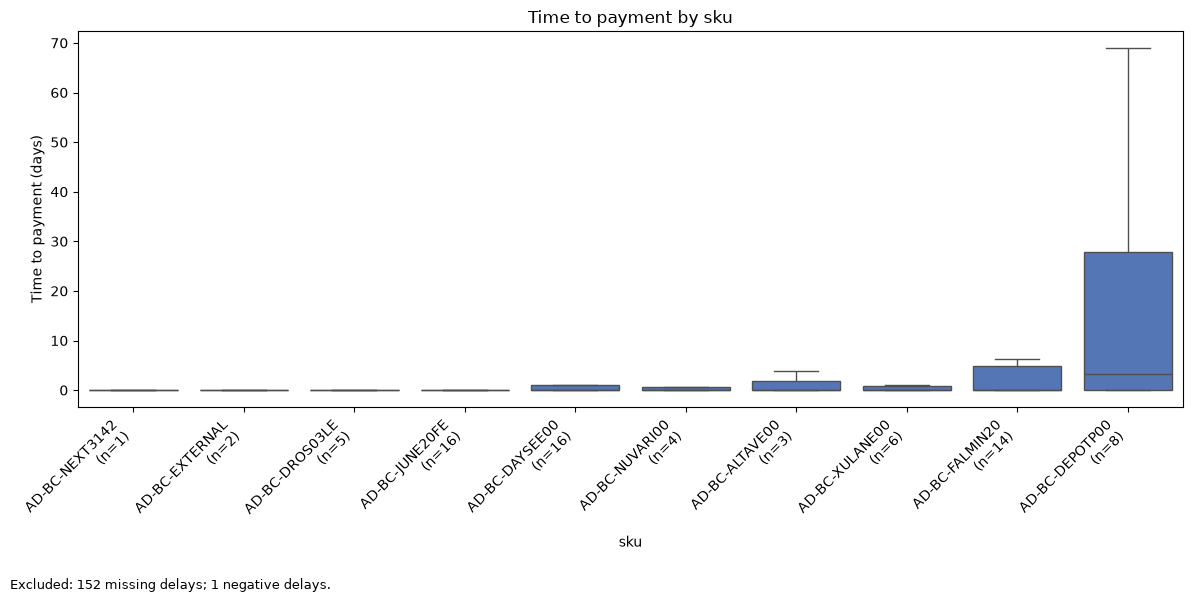

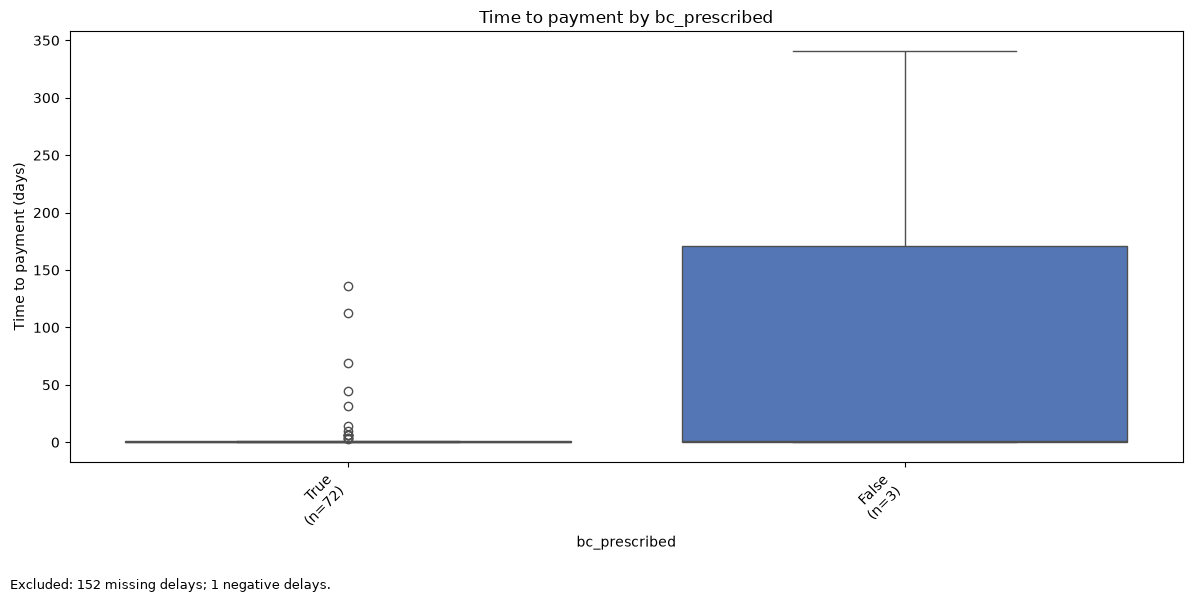

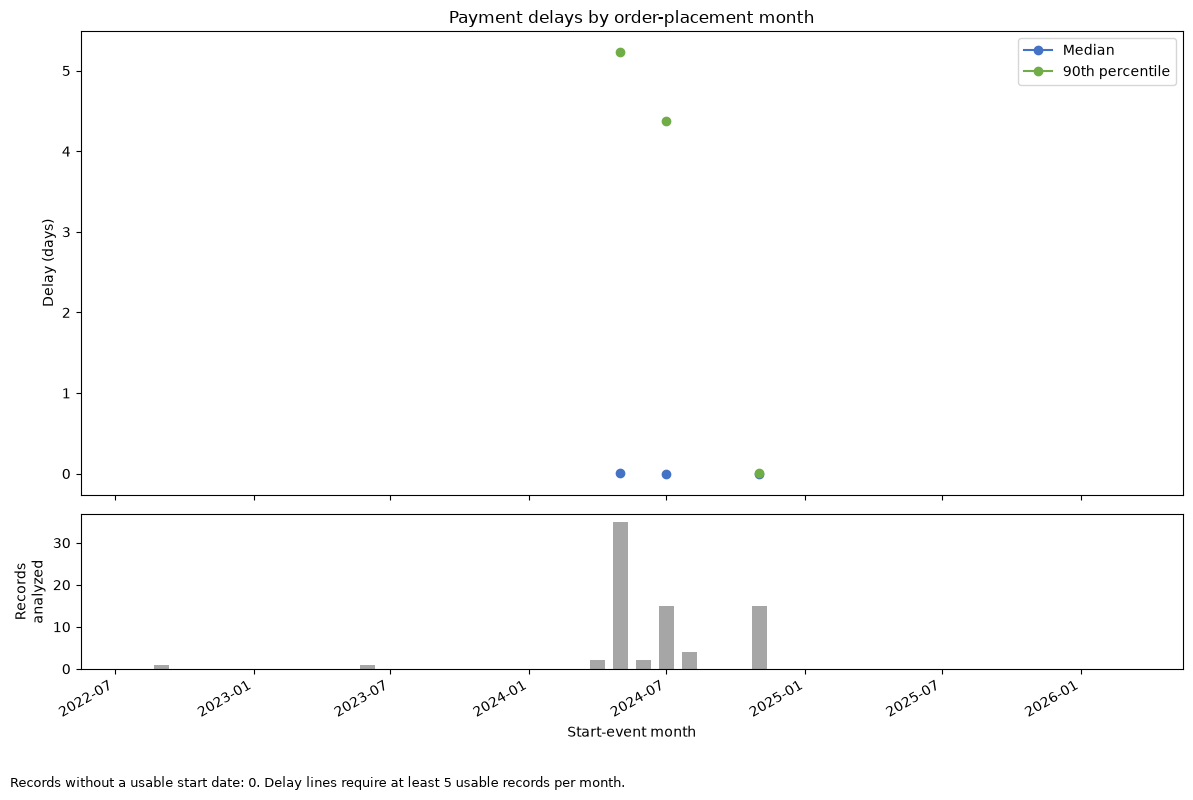

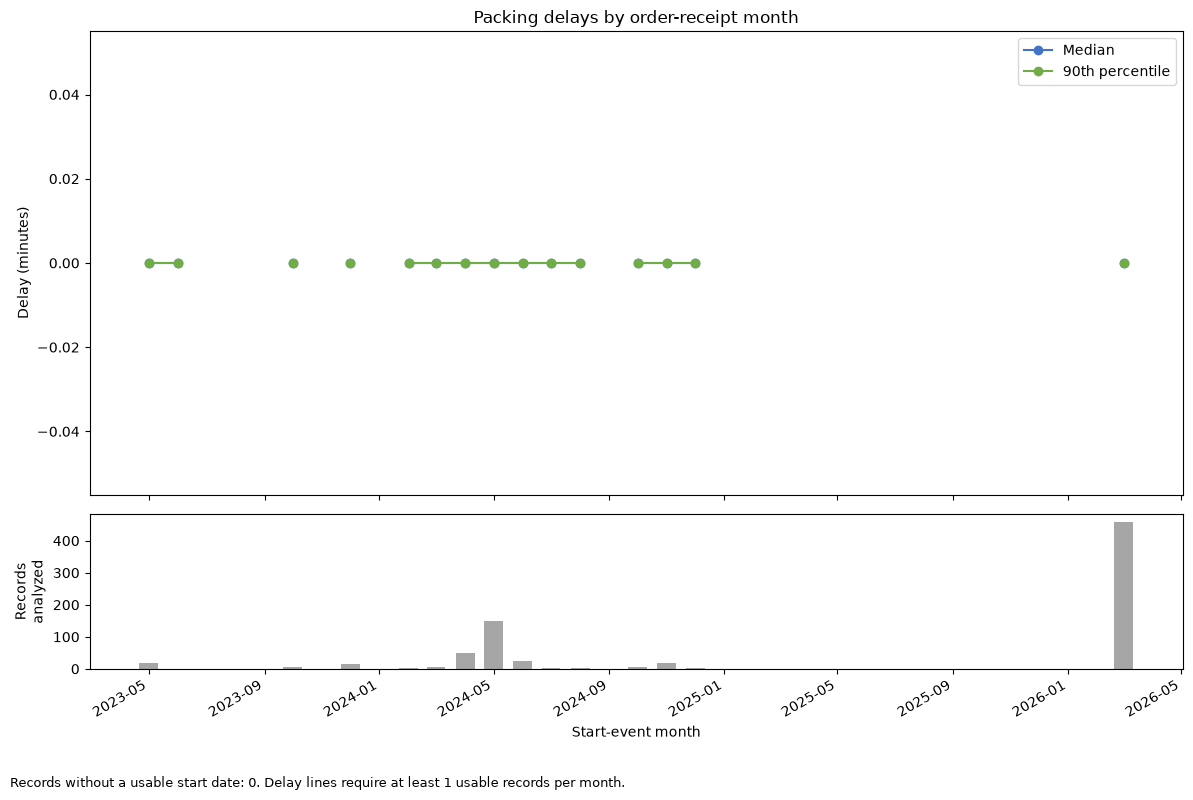

In [94]:
import importlib

# Payment delays by medication
display(payment_delay_summary(rx_orders, group="sku"))

fig = plot_payment_delay_by(
    rx_orders,
    group="sku",
    showfliers=False,
)
plt.show()

# Payment delays by birth-control flag
fig = plot_payment_delay_by(
    rx_orders,
    group="bc_prescribed",
)
plt.show()

# Monthly payment-delay trend
fig = plot_delay_trend(
    rx_orders,
    start_col="date_order_placed",
    end_col="date_order_paid",
    unit="days",
    min_n=5,  # CHANGE or use 1 to show every month with usable delays.
    title="Payment delays by order-placement month",
)
plt.show()

# Monthly packing-delay trend, loading directly from SQL
fig = plot_delay_trend(
    "RxPacked",
    conn=conn,
    start_col="order_receipt_date_time",
    end_col="packed_date_time",
    unit="minutes",
    title="Packing delays by order-receipt month",
)
plt.show()

In [95]:

missing = missing_summary(rx_orders)
quantities_by_bc = quantity_summary(rx_orders)
quantities_by_sku = quantity_summary(rx_orders, by="sku")




In [96]:

summary = order_status_summary(rx_orders)
display(summary)

,status,n_orders,percent_orders
0,(missing),206,90.350877
1,processed,21,9.210526
2,Archived,1,0.438596


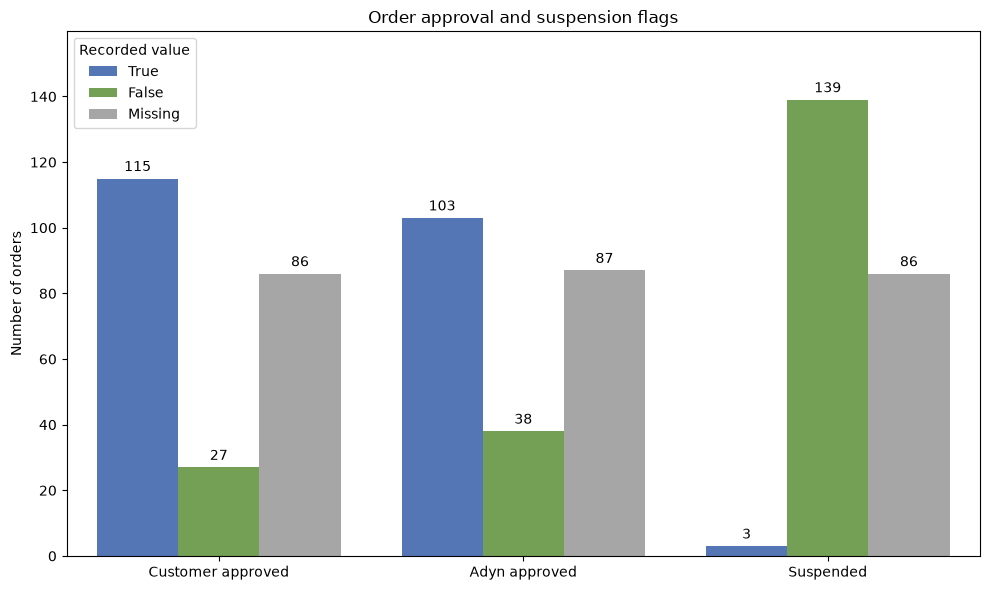

In [97]:
fig = plot_approval_flags(rx_orders)
plt.show()


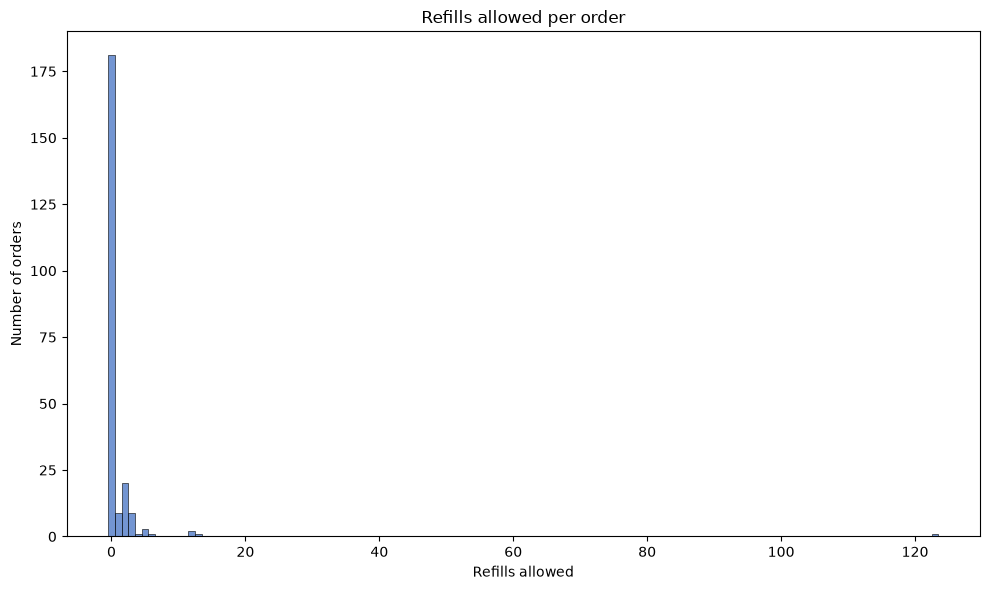

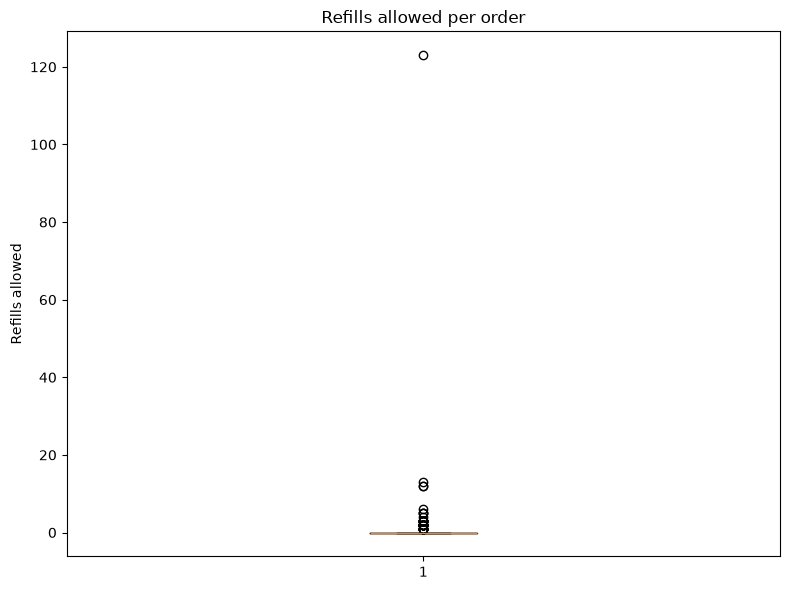

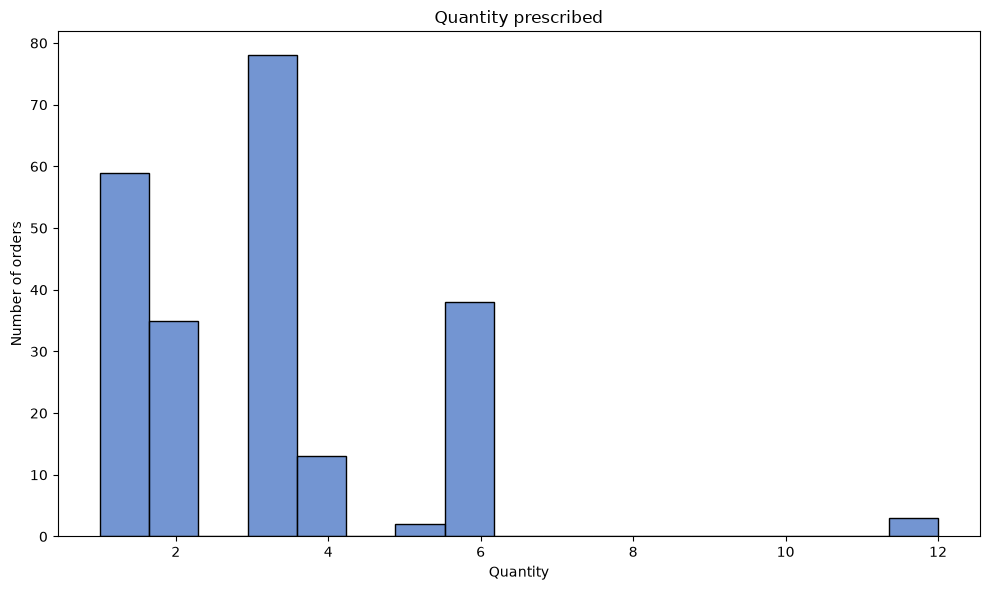

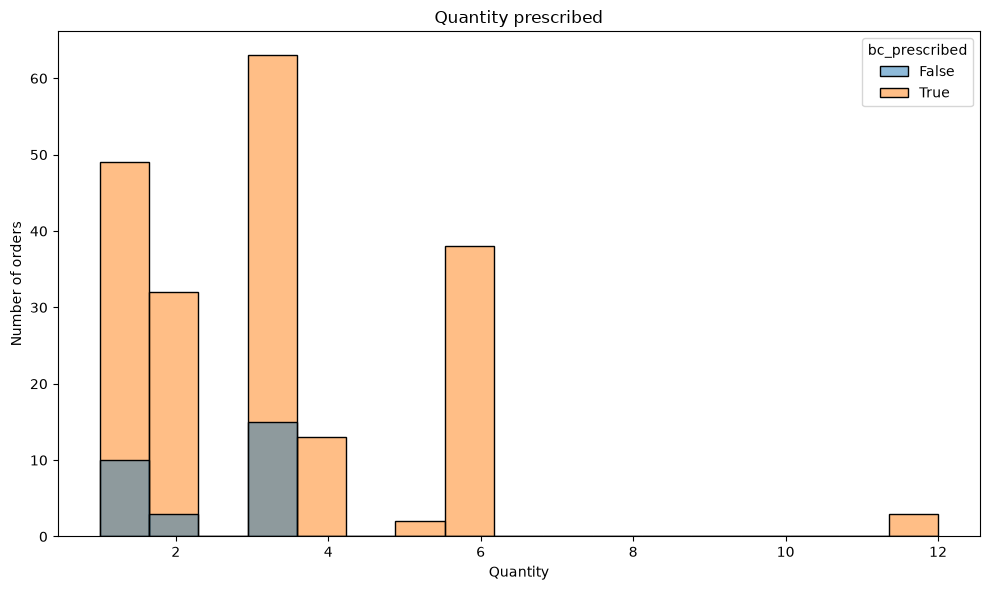

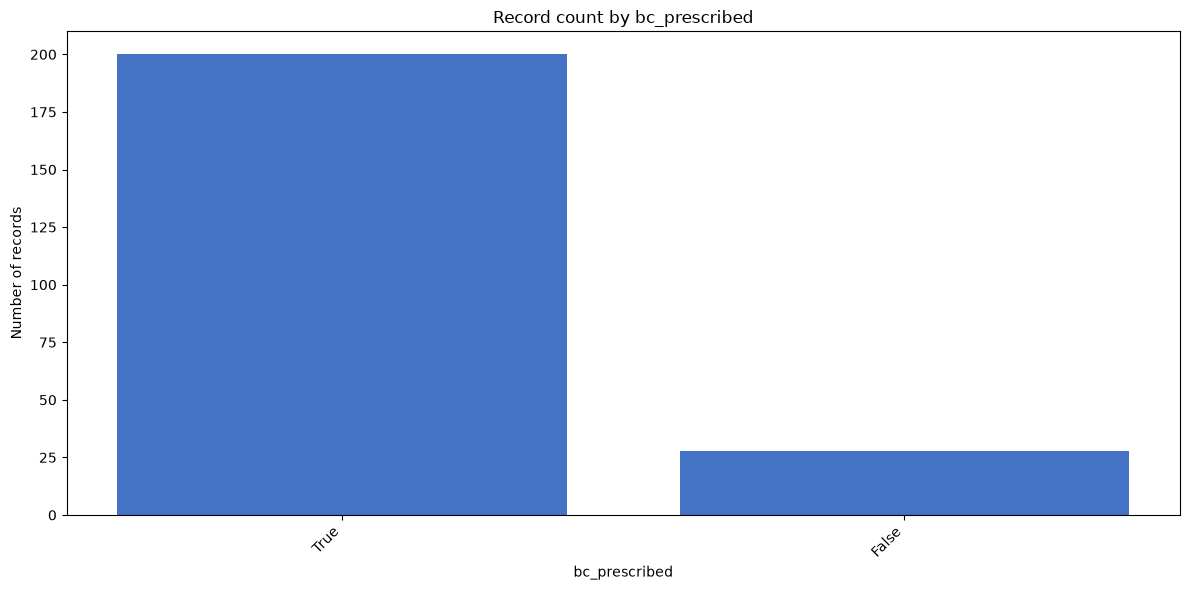

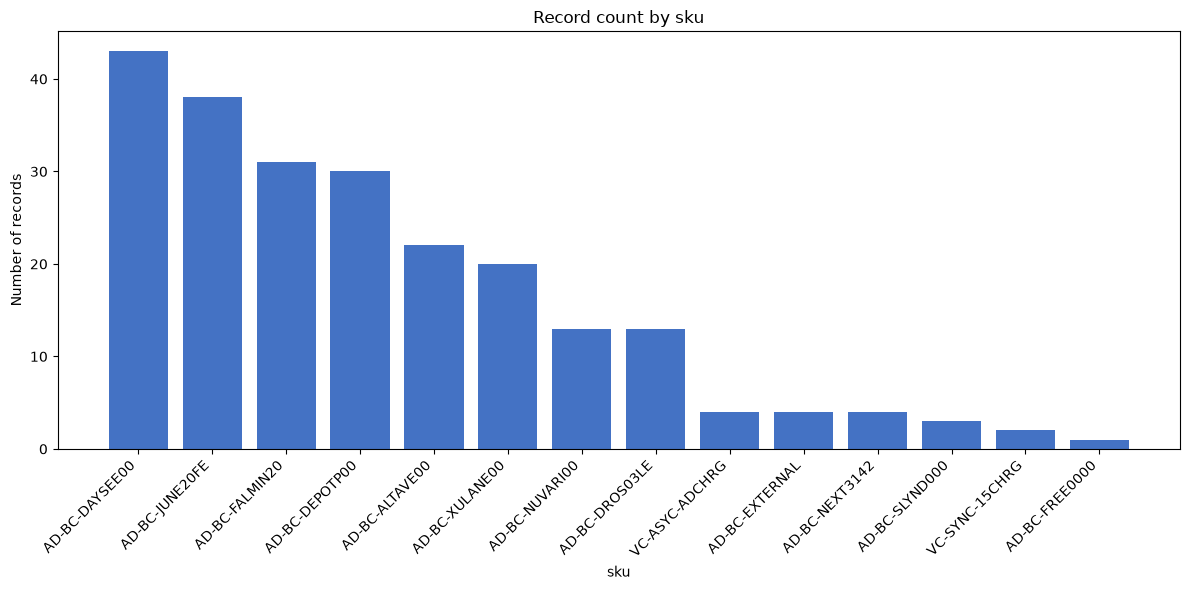

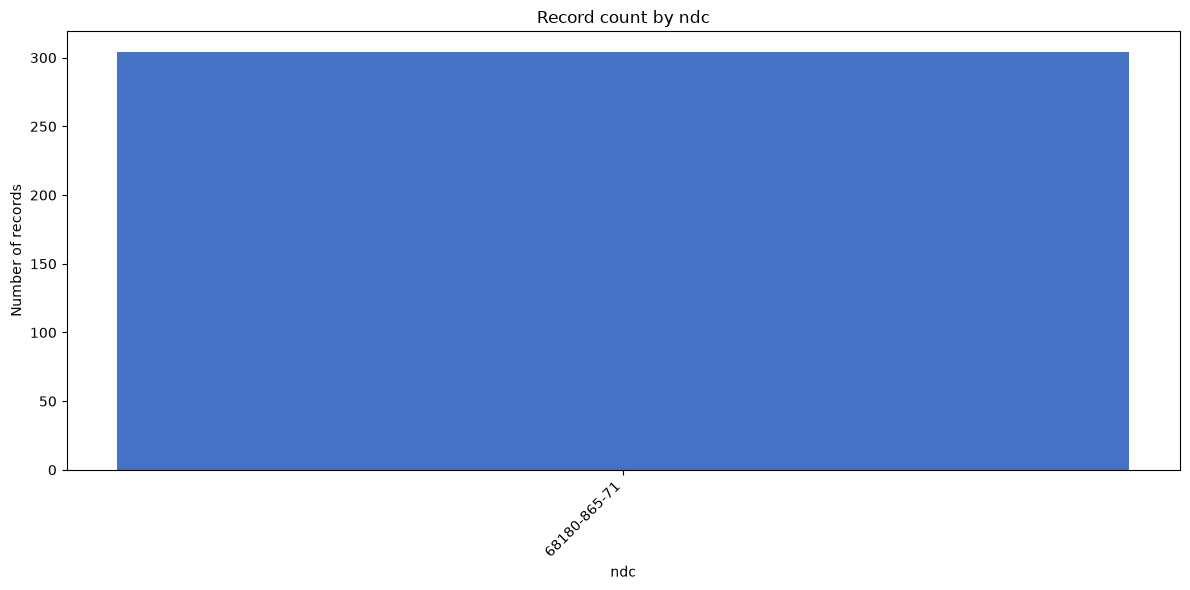

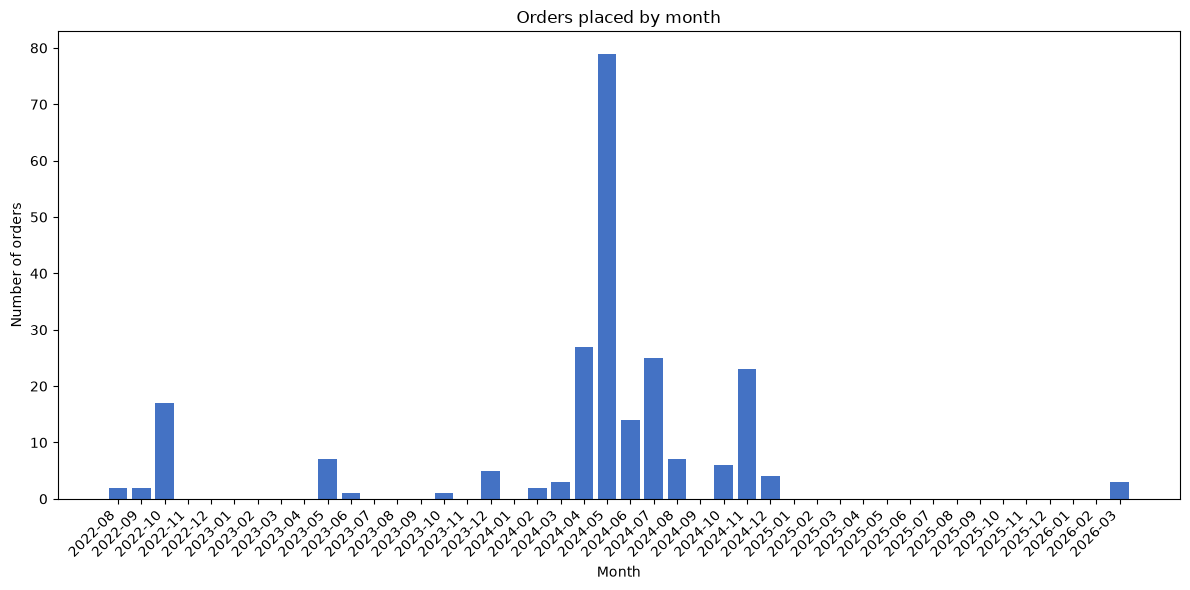

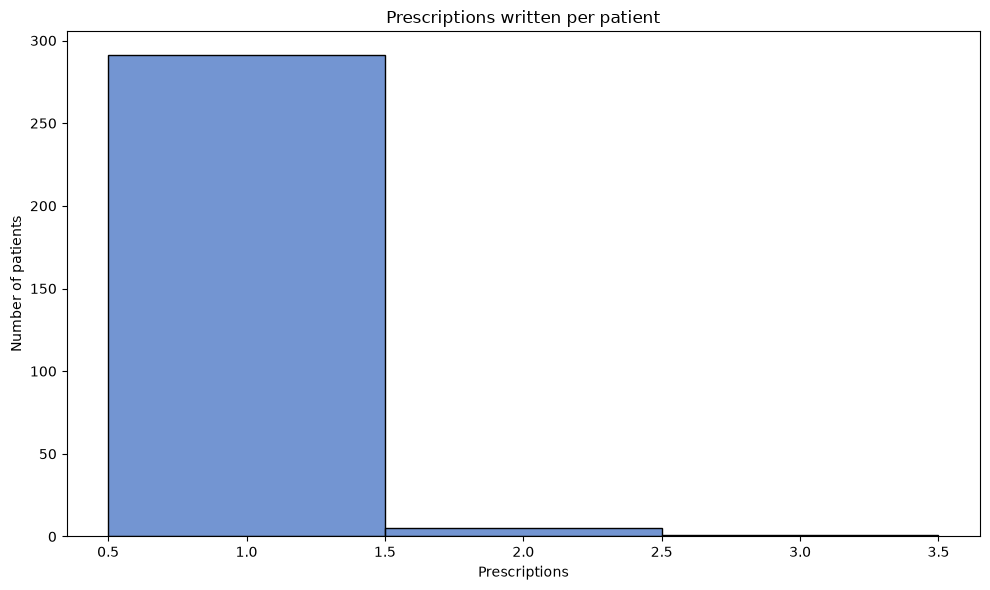

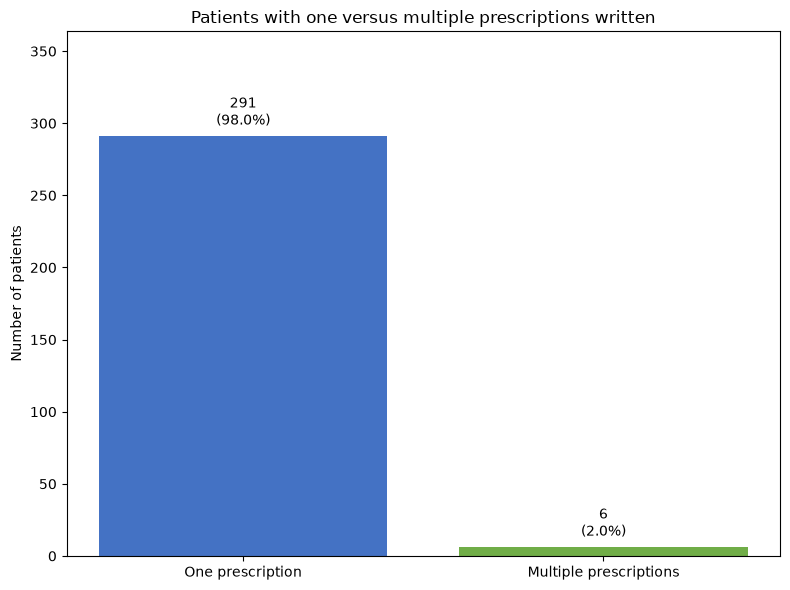

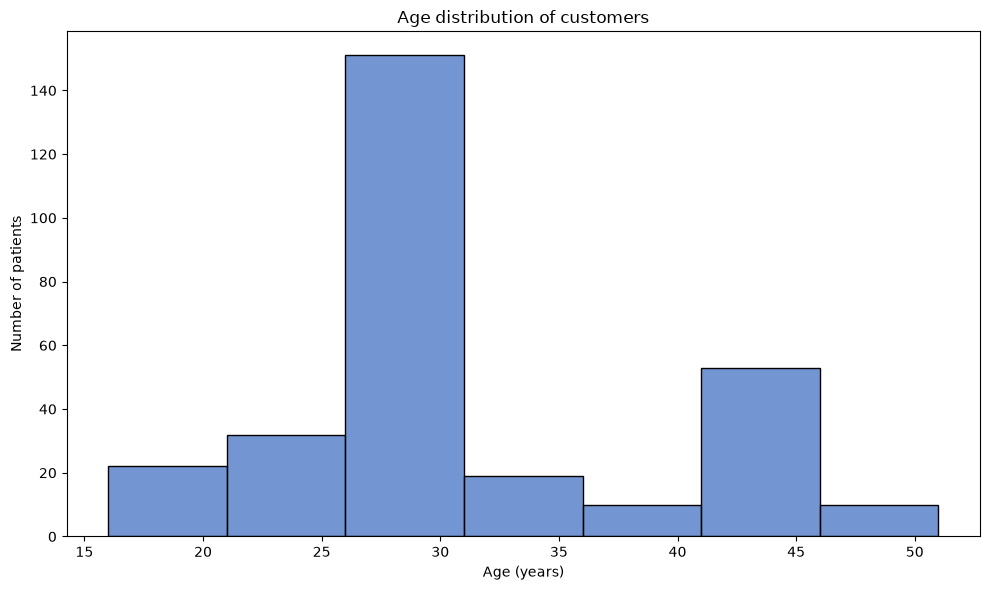

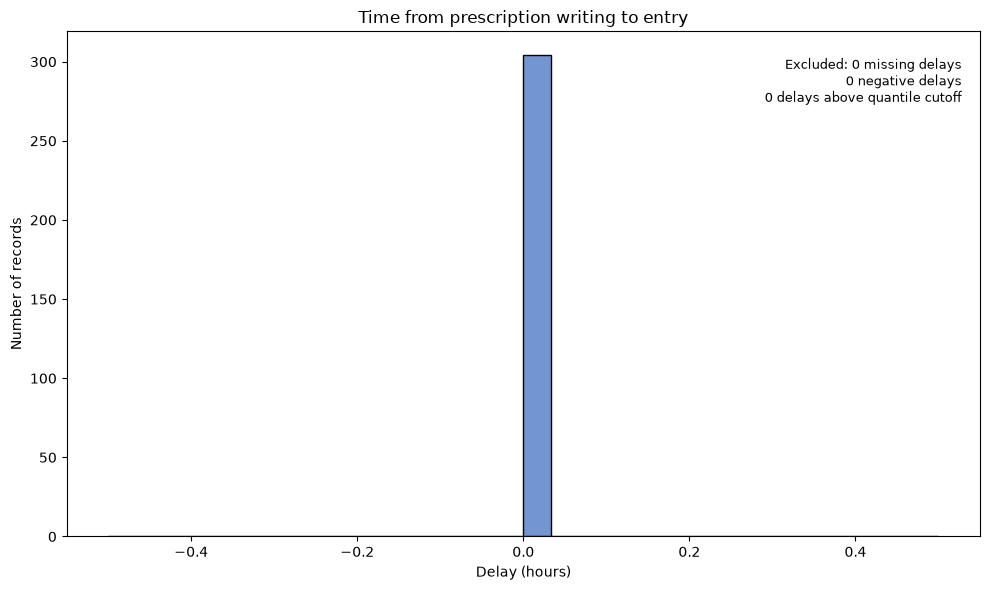

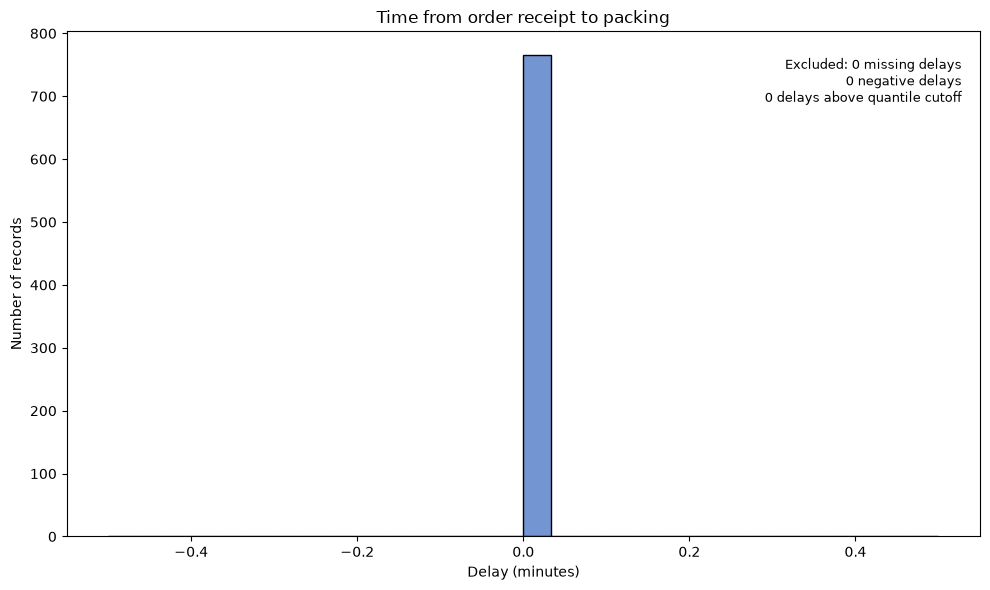

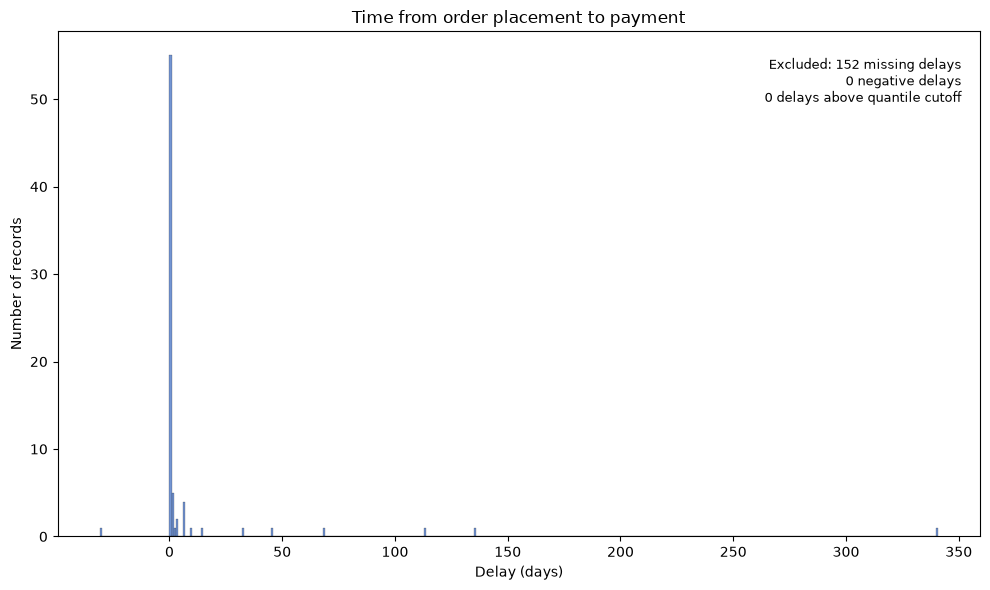

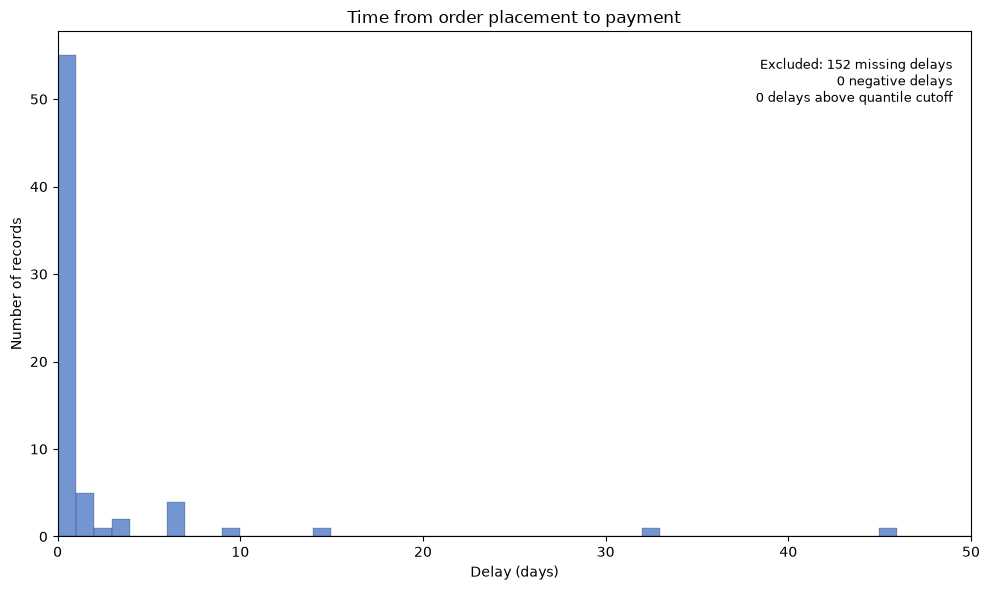

In [98]:
fig_refills = plot_refills(rx_orders)
fig_box_refills = plot_refills(rx_orders, kind="box")
fig_rx_quantity = plot_quantity(rx_orders)
fig_rx_quantity_bc = plot_quantity(rx_orders, by_bc=True)
fig_rx_orders_bc = plot_category_counts(rx_orders, "bc_prescribed")
fig_rx_orders_sku = plot_category_counts(rx_orders, "sku")
fig_rx_written_ndc = plot_category_counts(rx_written, "ndc")  # Separate filename from SKU plot.
fig_monthly_orders = plot_monthly_orders(rx_orders)
fig_prescriptions = plot_prescriptions_per_patient(rx_written)
fig_grouped_prescriptions = plot_prescriptions_per_patient(rx_written, grouped=True)
fig_customer_age = plot_customer_age(rx_written, as_of="2026-10-31")  # Change date or omit.
fig_entry_delay = plot_entry_delay(rx_written)
fig_packing_delay = plot_packing_delay("RxPacked", conn=conn)
fig_payment_delay = plot_payment_delay(rx_orders)
fig_payment_delay_adjust = plot_payment_delay(rx_orders, xlim=(0, 50), filename="payment_delay_zoom.png")
fig_state_shipments = plot_shipments_by_state("RxShipments", conn=conn)
plt.show()  # For Matplotlib; call fig.show() for the Plotly map.
fig_state_shipments.show()
plt.close()  # Close a Matplotlib figure when finished to free memory.


In [99]:
rx_orders.columns


Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

In [100]:
missing

,dtype,n_missing,share_missing,n_unique
id,str,0,0.000000,228
friendly_order_id,str,0,0.000000,228
customer_id,str,0,0.000000,45
stripe_customer_id,str,0,0.000000,45
status,str,206,0.903509,2
prescriber_id,str,0,0.000000,13
sku,str,0,0.000000,14
quantity,int64,0,0.000000,7
signetur,str,0,0.000000,50
note_to_pharmacy,str,0,0.000000,28


In [101]:
quantities_by_bc


,count,mean,median,std,min,max
bc_prescribed,,,,,,
False,28,2.178571,3.0,0.944911,1,3
True,200,3.140000,3.0,2.042365,1,12


In [102]:
quantities_by_sku

,count,mean,median,std,min,max
sku,,,,,,
AD-BC-ALTAVE00,22,3.136364,3.0,0.639602,3,6
AD-BC-DAYSEE00,43,2.372093,2.0,0.756661,2,4
AD-BC-DEPOTP00,30,1.200000,1.0,0.610257,1,3
AD-BC-DROS03LE,13,3.846154,3.0,1.344504,3,6
AD-BC-EXTERNAL,4,2.250000,2.0,1.500000,1,4
AD-BC-FALMIN20,31,1.516129,1.0,1.150970,1,5
AD-BC-FREE0000,1,3.000000,3.0,NaN,3,3
AD-BC-JUNE20FE,38,6.105263,6.0,1.997153,3,12
AD-BC-NEXT3142,4,3.000000,3.0,0.000000,3,3
